In [1]:
from pathlib import Path
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
PROJECT_ROOT = Path().resolve().parent.parent.parent

In [2]:
rad_path = PROJECT_ROOT / 'data' / 'interim' / 'MISR_RAD_O105254_P117_R00275_X17950487_18003012_Y0193187_0245712.nc'
cmv_path = PROJECT_ROOT / 'data' / 'interim' / 'MISR_CMV_O105254_P117_R17600_X17959150_17994350_Y0201850_0237050.nc'

rad = xr.load_dataset(rad_path)
cmv = xr.load_dataset(cmv_path)

In [3]:
cmv

<xarray.Dataset>
Dimensions:                 (som_x: 3, som_y: 3)
Coordinates:
  * som_x                   (som_x) float64 1.796e+07 1.798e+07 1.799e+07
  * som_y                   (som_y) float64 2.018e+05 2.194e+05 2.37e+05
Data variables:
    lat                     (som_x, som_y) float64 19.44 19.42 ... 19.11 19.09
    lon                     (som_x, som_y) float64 119.6 119.7 ... 119.7 119.9
    gamma                   (som_x, som_y) float64 1.654 1.655 ... 1.655 1.656
    CloudTopHeightOfMotion  (som_x, som_y) float32 521.1 531.3 ... 591.1 513.6
    CloudMotionNorthward    (som_x, som_y) float32 1.202 1.466 ... 1.004 0.09489
    CloudMotionEastward     (som_x, som_y) float32 1.594 1.463 ... -0.07763
Attributes:
    path:         117
    orbit:        105254
    block_range:  [75 75]
    resolution:   17600
    regionID:     P117_R17600_X17959150_17994350_Y0201850_0237050

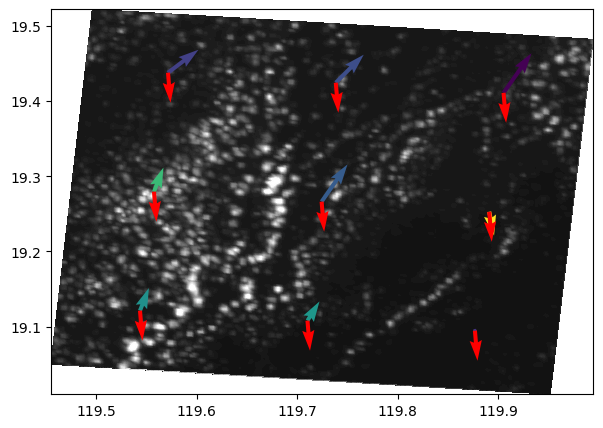

In [8]:
plot_kwargs = {
    'cmap':'gray',
    'vmin':0,
    'vmax':0.4,
    'levels':np.linspace(0, 0.4, 50)
}
f, ax = plt.subplots(1, 1, figsize=(7,5))
ax.tricontourf(
    np.ravel(rad.lon.data),
    np.ravel(rad.lat.data),
    np.ravel(rad.brf.isel(camera=4).data),
    **plot_kwargs
)
ax.quiver(
    np.ravel(cmv.lon.data),
    np.ravel(cmv.lat.data),
    np.ravel(cmv.CloudMotionEastward.data),
    np.ravel(cmv.CloudMotionNorthward.data),
    np.ravel(cmv.CloudTopHeightOfMotion)
)
ax.quiver(
    np.ravel(cmv.lon.data),
    np.ravel(cmv.lat.data),
    np.ravel(-np.cos(cmv.gamma.data)),
    np.ravel(-np.sin(cmv.gamma.data)),
    color='r'
)